# Movies Dataset Analysis
- by barisbatuhan
- link: https://www.kaggle.com/rounakbanik/the-movies-dataset

## Contents:
- Imported Libraries
- Reading the Data
- Data Clearing and Formatting
- Data Analysis
- What Can Be Done Next?

## Imported Libraries
- **pandas** for holding dataset and processing
- **numpy** for list operations etc.
- **matplotlib and seaborn** for graphics and data analysis
- **ast** for its herler functions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ast import literal_eval
import json
%matplotlib inline

## Reading the Data

In [2]:
!pip install kagglehub

In [3]:
import kagglehub
import os

# Download dataset
path = kagglehub.dataset_download("rounakbanik/the-movies-dataset")
print("Path to dataset files:", path)

# List files inside the dataset folder
print(os.listdir(path))

Path to dataset files: C:\Users\Admin\.cache\kagglehub\datasets\rounakbanik\the-movies-dataset\versions\7
['credits.csv', 'keywords.csv', 'links.csv', 'links_small.csv', 'movies_metadata.csv', 'ratings.csv', 'ratings_small.csv']


In [4]:
csv_path = os.path.join(path, "movies_metadata.csv")
df = pd.read_csv(csv_path, encoding="latin-1")  # encoding needed for special characters
print(df.head())

   adult                              belongs_to_collection    budget  \
0  False  {'id': 10194, 'name': 'Toy Story Collection', ...  30000000   
1  False                                                NaN  65000000   
2  False  {'id': 119050, 'name': 'Grumpy Old Men Collect...         0   
3  False                                                NaN  16000000   
4  False  {'id': 96871, 'name': 'Father of the Bride Col...         0   

                                              genres  \
0  [{'id': 16, 'name': 'Animation'}, {'id': 35, '...   
1  [{'id': 12, 'name': 'Adventure'}, {'id': 14, '...   
2  [{'id': 10749, 'name': 'Romance'}, {'id': 35, ...   
3  [{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...   
4                     [{'id': 35, 'name': 'Comedy'}]   

                               homepage     id    imdb_id original_language  \
0  http://toystory.disney.com/toy-story    862  tt0114709                en   
1                                   NaN   8844  tt0113497         

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\398231934.py:2: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path, encoding="latin-1")  # encoding needed for special characters


## Data Clearing and Formatting

### - Movies Metadata Dataset

In [5]:
df.head(5)

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


####  Columns to be Dropped
- **original_title**: since title column is also included and original_title column has non-ASCII characters, it can be dropped.
- **homepage**: there will be no analysis depending on the homepage of the movie, this column is uselesss for this specific analysis
- **imdb_id**: both ratings.csv and keywords.csv has id column to match with metadata dataset, thus no need for this column.
- **overview & tagline**: no text analysis will be made in this notebook. For retrieving the most important words, keywords.csv can be used
- **video & poster_path**: no image, video related processing will be made
- **spoken_languages**: original_language is included, no need

In [6]:
drop_df = ["homepage", "poster_path", "video", "imdb_id", "overview", "original_title", 
           "spoken_languages", "tagline"]
df = df.drop(drop_df, axis=1) # drops the selected columns
df = df.drop_duplicates(keep='first') # removes the duplicates from existing dataframe
df.dropna(how="all",inplace=True) # if each column is NaN or null in a row, drops this row

In [7]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45453 entries, 0 to 45465
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45453 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45453 non-null  object 
 3   genres                 45453 non-null  object 
 4   id                     45453 non-null  object 
 5   original_language      45442 non-null  object 
 6   popularity             45448 non-null  object 
 7   production_companies   45450 non-null  object 
 8   production_countries   45450 non-null  object 
 9   release_date           45366 non-null  object 
 10  revenue                45447 non-null  float64
 11  runtime                45190 non-null  float64
 12  status                 45366 non-null  object 
 13  title                  45447 non-null  object 
 14  vote_average           45447 non-null  float64
 15  vote_co

Out of 45449 rows, there are 6 rows with no title. Let's drop that one, too. Moreover, the types of **id, popularity and budget** is object, although they had to be numeric. Errors will be handled with coerce option, thus invalid parsing will be set as NaN. Also converting release_date to datetime instead of object and extracting the year data may be helpful.

In [8]:
df.dropna(subset=["title"], inplace=True)
df["id"] =pd.to_numeric(df['id'], errors='coerce', downcast="integer")
df["popularity"] =pd.to_numeric(df['popularity'], errors='coerce', downcast="float") 
df["budget"] =pd.to_numeric(df['budget'], errors='coerce', downcast="float") 
df['release_date'] = pd.to_datetime(df['release_date'])
df['release_year'] = df['release_date'].dt.year

As we can see from the dataset itself and *info()* function, **belongs_to_collection** column has too many null entries, therefore instead of giving the collection name, we can convert the data to 0 and 1, 0 for not belonging and 1 for belonging. 

In [9]:
df['belongs_to_collection'] = df['belongs_to_collection'].fillna("None")
df['belongs_to_collection'] = (df['belongs_to_collection'] != "None").astype(int)

In adult column, only 9 True values are present, this information will not give us anything significant, thus, that column is also dropped.

In [10]:
df["adult"].value_counts()

adult
False    45438
True         9
Name: count, dtype: int64

In [11]:
df.drop(["adult"], inplace=True, axis=1)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45447 entries, 0 to 45465
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   belongs_to_collection  45447 non-null  int64         
 1   budget                 45447 non-null  float64       
 2   genres                 45447 non-null  object        
 3   id                     45447 non-null  int32         
 4   original_language      45436 non-null  object        
 5   popularity             45447 non-null  float32       
 6   production_companies   45447 non-null  object        
 7   production_countries   45447 non-null  object        
 8   release_date           45363 non-null  datetime64[ns]
 9   revenue                45447 non-null  float64       
 10  runtime                45190 non-null  float64       
 11  status                 45366 non-null  object        
 12  title                  45447 non-null  object        
 13  vote_a

For **status** column, less than 100 entries are null and it may be a good idea to fill these with most common data. For **runtime**, again a similar case occurs and it can be handled by filling NaN values with the mean.

In [13]:
df["status"].fillna(df["status"].value_counts().idxmax(), inplace=True)
df["runtime"] = df["runtime"].replace(0, np.nan)
df["runtime"].fillna(df["runtime"].mean(), inplace=True) 

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\847444079.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["status"].fillna(df["status"].value_counts().idxmax(), inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\847444079.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behave

Since there are around 70 null **release_date** entries and filling that is not logical, they will be dropped, too. And also 1 row that has null as in column **original_language** may be dropped.

In [14]:
df.dropna(subset=["release_date"],inplace=True)
df.dropna(subset=["original_language"],inplace=True)

There are some cells, which have stringified list of json inputs such as **genres, production_companies and production_countries**. For easier processing, these have to be converted into list of inputs. The function below achieves this:

In [15]:
# converts json list to list of inputs (from the label specified with 'wanted' parameter)
def json_to_arr(cell, wanted = "name"): 
    cell = literal_eval(cell)
    if cell == [] or (isinstance(cell, float) and cell.isna()):
        return np.nan
    result = []
    counter = 0
    for element in cell:
        if counter < 3:
            result.append(element[wanted])
            counter += 1
        else:
            break
    return result[:3]

Let's apply this function to specified 3 parameters:

In [16]:
df[['genres']] = df[['genres']].applymap(json_to_arr)
df[['production_countries']] = df[['production_countries']].applymap(lambda row: 
                                                                     json_to_arr(row, "iso_3166_1"))
df[['production_companies']] = df[['production_companies']].applymap(json_to_arr)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\3250636073.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['genres']] = df[['genres']].applymap(json_to_arr)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\3250636073.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['production_countries']] = df[['production_countries']].applymap(lambda row:
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\3250636073.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['production_companies']] = df[['production_companies']].applymap(json_to_arr)


Many entries of **budget and revenue** are 0. However, instead of 0, having NaN is more logical for seeing how many entries are actually available.

In [17]:
df['budget'] = df['budget'].replace(0, float('nan'))
df['revenue'] = df['revenue'].replace(0, float('nan'))

In [18]:
print("Number of rows with budget < 100: ", len((df[(df["budget"].notna())&(df["budget"] < 100)])))
print("Number of rows with budget > 100 and < 1000: ", len(df[(df["budget"].notna())&(df["budget"] > 100)
                                                              &(df["budget"] < 1000)]))
print("Number of rows with budget > 1000 and < 10000: ", len(df[(df["budget"].notna())&(df["budget"] > 1000)
                                                              &(df["budget"] < 10000)]))

Number of rows with budget < 100:  137
Number of rows with budget > 100 and < 1000:  101
Number of rows with budget > 1000 and < 10000:  52


There are some rows that have a budget and revenue value, that are not actually scaled. By checking some of the notebooks shared, I have decided to move on with the scaling function below. For example, if the value is 1, then it scales to 1 million. If an example will be given from the true data:
- id: 17402
- Title: Miami Rhapsody
- Production Company: Hollywood Pictures	
- Date: 1995-01-27	
- Budget: 6
- Revenue: 5 (by looking IMDB, actual revenue can be seen as around 5 million)

In [19]:
def scale_money(num):
    if num < 100:
        return num * 1000000
    elif num >= 100 and num < 1000:
        return num * 10000
    elif num >= 1000 and num < 10000:
        return num *100
    else:
        return num

In [20]:
df[['budget', 'revenue']] = df[['budget', 'revenue']].applymap(scale_money)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\1487942327.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['budget', 'revenue']] = df[['budget', 'revenue']].applymap(scale_money)


After these steps, the columns can be osberved to see how many null or NaN entries there are. So, a heatmap and data is below:

<Axes: >

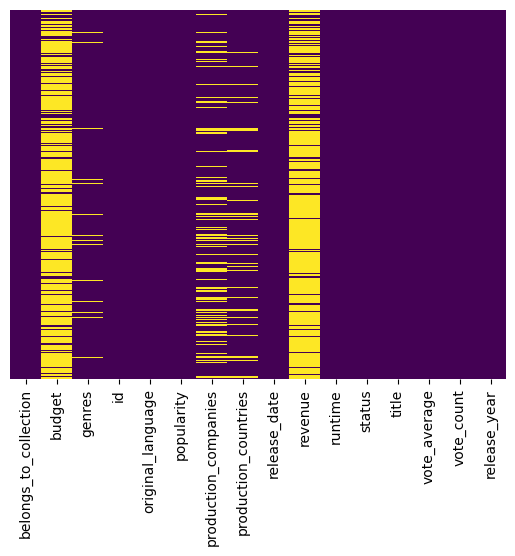

In [21]:
sns.heatmap(df.isnull(), yticklabels = False, cbar = False, cmap = 'viridis')

In [22]:
print("NaN Genres Count: ", len(df[df["genres"].isna()]))
print("NaN Revenue Count: ", len(df[df['revenue'].isna()])) 
print("NaN Budget Count: ", len(df[df['budget'].isna()])) 
print("NaN Production Company Count: ", len(df[df["production_companies"].isna()]))
print("NaN Production Country Count: ", len(df[df["production_countries"].isna()]))

NaN Genres Count:  2383
NaN Revenue Count:  37947
NaN Budget Count:  36467
NaN Production Company Count:  11789
NaN Production Country Count:  6207


For **revenue, budget and production company** filling the values with the most appearing entry or mean is not so logical, since the number of null or NaN entries are huge (More than %20 of whoel dataset). But for **genres and country** it may be done. The function below analyzes the most occuring values for columns in list formats.

In [23]:
# returns the values and occurance times or "limiter" amount of different parameters in a 2D list
def list_counter(col, limiter = 9999, log = True):
    result = dict()
    for cell in col:
        if isinstance(cell, float):
            continue
        for element in cell:
            if element in result:
                result[element] += 1
            else:
                result[element] = 1
    if log:
        print("Size of words:", len(result))
    result = {k: v for k, v in sorted(result.items(), key=lambda item: item[1], reverse=True)}
    if log:
        print("Sorted result is:")
    counter = 1
    sum_selected = 0
    total_selected = 0
    rest = 0
    returned = []
    for i in result: 
        if counter > limiter:
            total_selected += result[i]
        else:
            counter += 1
            sum_selected += result[i]
            total_selected += result[i]
            if log:
                print(result[i], " - ", i) 
            returned.append([i, result[i]])
    if log:
        print("Covered:", sum_selected, "out of", total_selected, "\n")
    return returned

<Axes: xlabel='genres'>

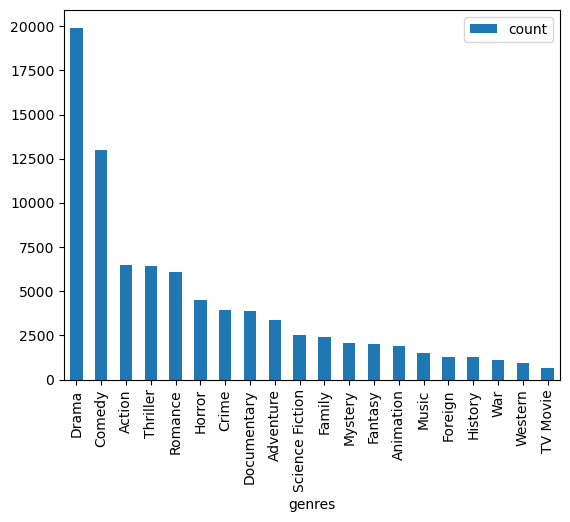

In [24]:
genres_occur = list_counter(df["genres"].values, log=False)
genres = pd.DataFrame.from_records(genres_occur, columns=["genres", "count"])
genres.plot(kind = 'bar', x="genres")

<Axes: xlabel='countries'>

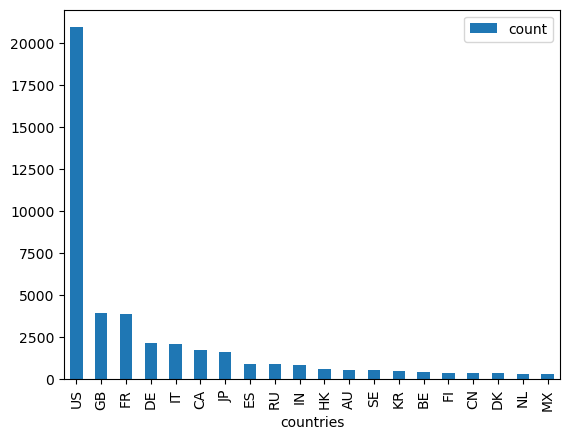

In [25]:
countries_occur = list_counter(df["production_countries"].values, log=False)
countries = pd.DataFrame.from_records(countries_occur, columns=["countries", "count"])
countries.head(20).plot(kind = 'bar', x="countries")

<Axes: xlabel='companies'>

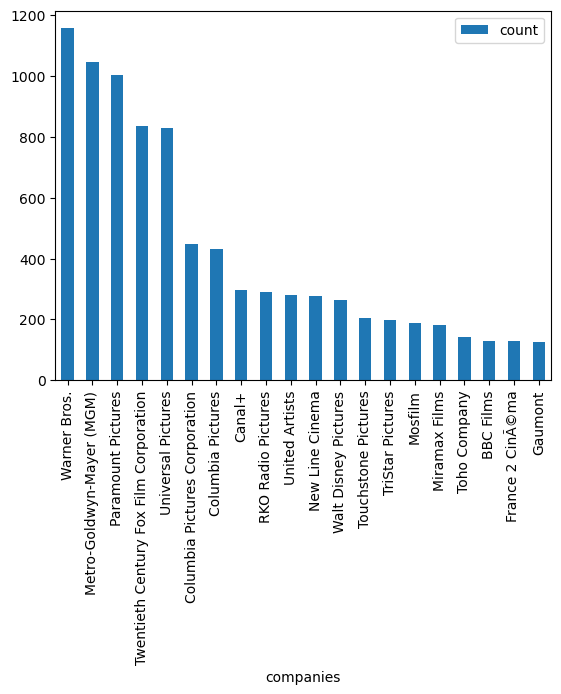

In [26]:
companies_occur = list_counter(df["production_companies"].values, log=False)
companies = pd.DataFrame.from_records(companies_occur, columns=["companies", "count"])
companies.head(20).plot(kind = 'bar', x="companies")

In **genres** *Drama* is the most occurring one with 20189 and in **production_countries** *US* is the most frequent entry. These can be placed into NA cells of these columns:

In [27]:
def fill_na_with_list(cell, data):
    if isinstance(cell, float):
        return data
    else:
        return cell

In [28]:
df[['genres']] = df[['genres']].applymap(lambda row:
                                        fill_na_with_list(row, [genres_occur[0][0]]))
df[['production_countries']] = df[['production_countries']].applymap(lambda row: 
                                        fill_na_with_list(row, [countries_occur[0][0]]))

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\3746850178.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['genres']] = df[['genres']].applymap(lambda row:
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\3746850178.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df[['production_countries']] = df[['production_countries']].applymap(lambda row:


In [29]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 45352 entries, 0 to 45465
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   belongs_to_collection  45352 non-null  int64         
 1   budget                 8885 non-null   float64       
 2   genres                 45352 non-null  object        
 3   id                     45352 non-null  int32         
 4   original_language      45352 non-null  object        
 5   popularity             45352 non-null  float32       
 6   production_companies   33563 non-null  object        
 7   production_countries   45352 non-null  object        
 8   release_date           45352 non-null  datetime64[ns]
 9   revenue                7405 non-null   float64       
 10  runtime                45352 non-null  float64       
 11  status                 45352 non-null  object        
 12  title                  45352 non-null  object        
 13  vote_a

In [30]:
df["profit"] = df["revenue"] - df["budget"]
df[["popularity", "revenue", "budget", "runtime", "vote_average","profit", "release_year"]].describe()

,popularity,revenue,budget,runtime,vote_average,profit,release_year
count,45352.000000,7.405000e+03,8.885000e+03,45352.000000,45352.000000,5.381000e+03,45352.000000
mean,2.927157,6.915759e+07,2.196976e+07,97.503186,5.624663,5.927712e+07,1991.884503
std,6.010854,1.463353e+08,3.437129e+07,33.931016,1.914703,1.395365e+08,24.047552
min,0.000000,1.000000e+04,1.000000e+04,1.000000,0.000000,-1.657101e+08,1874.000000
25%,0.389193,2.945600e+06,2.100000e+06,87.000000,5.000000,-1.484190e+06,1978.000000
50%,1.130980,1.729238e+07,8.700000e+06,96.000000,6.000000,1.125000e+07,2001.000000
75%,3.693458,6.791866e+07,2.549663e+07,107.000000,6.800000,6.222979e+07,2010.000000
max,547.488281,2.787965e+09,3.800000e+08,1256.000000,10.000000,2.550965e+09,2020.000000


Since difference between min and max values for **budget, revenue and profit** is not so small, I have normalized these. In order to preserve the signs of the parameters, the formula of normalization is applied as: 
- value / (max - min)

In [31]:
min_val = df["budget"].min()
max_val = df["budget"].max()
df[["budget", "revenue", "profit"]] = df[["budget", "revenue", "profit"]].apply(lambda x: 
                                                            x / (max_val - min_val))

From a notebook, I have found a way to arrange **vote_counts** and **vote_averages** with a weighted manner, since there are lots of 0s in the dataset in both columns. The process is implemented below and explained as:
- Weighted Rating for a row (WR) = [(v + 1) / (v + m) * R] + [m / (m + v) * C]
- v: number of votes for the movie
- m: minimum votes required to be listed in the chart (quantile 0.75)
- R: average rating of the movie 
- C: mean vote across the whole report

In [32]:
vote_counts = df[df['vote_count'].notnull()]['vote_count'].astype('int')
vote_averages = df[df['vote_average'].notnull()]['vote_average'].astype('int')
C = vote_averages.mean()
m = vote_counts.quantile(0.75)
def weighted_rating(data):
    v = data['vote_count'] + 1 # added +1
    R = data['vote_average']
    return (v / (v + m) * R) + (m / (m + v) * C)

df['weighted_rating'] = df.apply(weighted_rating, axis=1)

### - Keywords Dataset

First the csv file is read and head if the file is printed to see the format:

In [33]:
csv_path = os.path.join(path, "keywords.csv")
df_kwrd = pd.read_csv(csv_path, encoding="latin-1")  # encoding needed for special characters
print(df.head())

   belongs_to_collection    budget                        genres     id  \
0                      1  0.078949   [Animation, Comedy, Family]    862   
1                      0  0.171057  [Adventure, Fantasy, Family]   8844   
2                      1       NaN             [Romance, Comedy]  15602   
3                      0  0.042106      [Comedy, Drama, Romance]  31357   
4                      1       NaN                      [Comedy]  11862   

  original_language  popularity  \
0                en   21.946943   
1                en   17.015539   
2                en   11.712900   
3                en    3.859495   
4                en    8.387519   

                                production_companies production_countries  \
0                          [Pixar Animation Studios]                 [US]   
1  [TriStar Pictures, Teitler Film, Interscope Co...                 [US]   
2                     [Warner Bros., Lancaster Gate]                 [US]   
3           [Twentieth Century

As one can see, **keywords** format is stringified list of json and it can be converted to simple list with using the function written above and problematic ones can be calculated:

In [34]:
df_kwrd["keywords"] = df_kwrd[['keywords']].applymap(json_to_arr)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\686009246.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_kwrd["keywords"] = df_kwrd[['keywords']].applymap(json_to_arr)


In [35]:
df_kwrd.dropna(inplace=True)

<Axes: xlabel='keywords'>

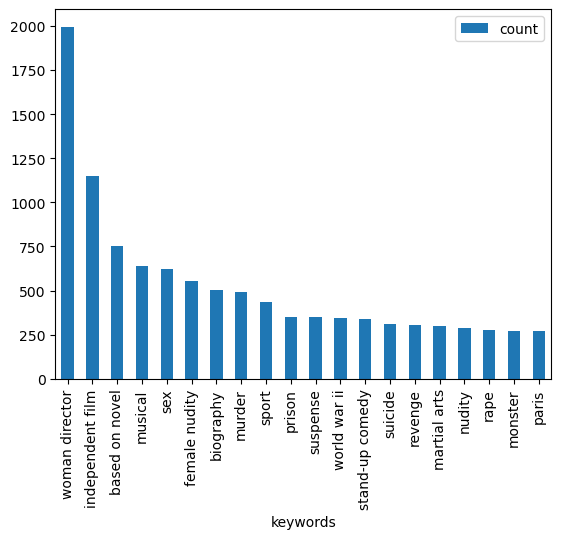

In [36]:
keywords_occur = list_counter(df_kwrd["keywords"].values, log=False)
keywords = pd.DataFrame.from_records(keywords_occur, columns=["keywords", "count"])
keywords.head(20).plot(kind = 'bar', x="keywords")

Since **id** parameters in both metadata and keywords directing to the same movie, the datasets can be merged.

In [37]:
df = pd.merge(df, df_kwrd, on=['id'], how='left')

In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45895 entries, 0 to 45894
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   belongs_to_collection  45895 non-null  int64         
 1   budget                 8974 non-null   float64       
 2   genres                 45895 non-null  object        
 3   id                     45895 non-null  int32         
 4   original_language      45895 non-null  object        
 5   popularity             45895 non-null  float32       
 6   production_companies   33986 non-null  object        
 7   production_countries   45895 non-null  object        
 8   release_date           45895 non-null  datetime64[ns]
 9   revenue                7475 non-null   float64       
 10  runtime                45895 non-null  float64       
 11  status                 45895 non-null  object        
 12  title                  45895 non-null  object        
 13  v

### - Credits Dataset

First the dataset is read and first couple of columns are printed to see the appearance of the data:

In [39]:
csv_path = os.path.join(path, "credits.csv")
df_cr = pd.read_csv(csv_path, encoding="latin-1")  # encoding needed for special characters
print(df.head())

   belongs_to_collection    budget                        genres     id  \
0                      1  0.078949   [Animation, Comedy, Family]    862   
1                      0  0.171057  [Adventure, Fantasy, Family]   8844   
2                      1       NaN             [Romance, Comedy]  15602   
3                      0  0.042106      [Comedy, Drama, Romance]  31357   
4                      1       NaN                      [Comedy]  11862   

  original_language  popularity  \
0                en   21.946943   
1                en   17.015539   
2                en   11.712900   
3                en    3.859495   
4                en    8.387519   

                                production_companies production_countries  \
0                          [Pixar Animation Studios]                 [US]   
1  [TriStar Pictures, Teitler Film, Interscope Co...                 [US]   
2                     [Warner Bros., Lancaster Gate]                 [US]   
3           [Twentieth Century

Since cast and crew type is stringified list of json, we can again extract the names from the cast and directors from the crew.

In [40]:
df_cr["cast"] = df_cr[['cast']].applymap(json_to_arr)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\4039540436.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_cr["cast"] = df_cr[['cast']].applymap(json_to_arr)


In [41]:
def get_director(x):
    x = literal_eval(x)
    for i in x:
        if i == "[]" or isinstance(i, float):
            return np.nan
        if i['job'] == 'Director':
            return i['name']
    return np.nan

df_cr['director'] = df_cr['crew'].apply(get_director)
df_cr.drop(["crew"], axis=1, inplace=True)

If there are cells with both missing cast and director columns, they should be dropped:

In [42]:
print("Entries with no cast:", len(df_cr[df_cr["cast"].isna()]))
print("Entries with no directors:", len(df_cr[df_cr["director"].isna()]))
print("Entries missing both:", len(df_cr[(df_cr["cast"].isna())&(df_cr["director"].isna())]))
df_cr.drop(df_cr[(df_cr["cast"].isna())&(df_cr["director"].isna())].index, inplace=True)

Entries with no cast: 2418
Entries with no directors: 887
Entries missing both: 437


The **id** of metadata and **id** of credits columns point to the same movies, thus, both datasets can be converged.

In [43]:
df = pd.merge(df, df_cr, on=['id'], how='left')

The final situation in the main dataframe is below:

In [44]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45986 entries, 0 to 45985
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   belongs_to_collection  45986 non-null  int64         
 1   budget                 9010 non-null   float64       
 2   genres                 45986 non-null  object        
 3   id                     45986 non-null  int32         
 4   original_language      45986 non-null  object        
 5   popularity             45986 non-null  float32       
 6   production_companies   34053 non-null  object        
 7   production_countries   45986 non-null  object        
 8   release_date           45986 non-null  datetime64[ns]
 9   revenue                7509 non-null   float64       
 10  runtime                45986 non-null  float64       
 11  status                 45986 non-null  object        
 12  title                  45986 non-null  object        
 13  v

In [45]:
df.head(3)

,belongs_to_collection,budget,genres,id,original_language,popularity,production_companies,production_countries,release_date,revenue,...,status,title,vote_average,vote_count,release_year,profit,weighted_rating,keywords,cast,director
0,1,0.078949,"[Animation, Comedy, Family]",862,en,21.946943,[Pixar Animation Studios],[US],1995-10-30,0.983063,...,Released,Toy Story,7.7,5415.0,1995.0,0.904113,7.684720,"[jealousy, toy, boy]","[Tom Hanks, Tim Allen, Don Rickles]",John Lasseter
1,0,0.171057,"[Adventure, Fantasy, Family]",8844,en,17.015539,"[TriStar Pictures, Teitler Film, Interscope Co...",[US],1995-12-15,0.691590,...,Released,Jumanji,6.9,2413.0,1995.0,0.520533,6.877093,"[board game, disappearance, based on children'...","[Robin Williams, Jonathan Hyde, Kirsten Dunst]",Joe Johnston
2,1,NaN,"[Romance, Comedy]",15602,en,11.712900,"[Warner Bros., Lancaster Gate]",[US],1995-12-22,NaN,...,Released,Grumpier Old Men,6.5,92.0,1995.0,NaN,6.165549,"[fishing, best friend, duringcreditsstinger]","[Walter Matthau, Jack Lemmon, Ann-Margret]",Howard Deutch


## Data Analysis

First of all, let's list top 10 movies regarding **weighted_rating and popularity and profit**:

In [46]:
df.sort_values('weighted_rating', ascending=False)[["title", "director", "genres", "profit", 
                                                    "popularity", "weighted_rating"]].head(10)

,title,director,genres,profit,popularity,weighted_rating
10338,Dilwale Dulhania Le Jayenge,Aditya Chopra,"[Comedy, Drama, Romance]",0.228427,34.457024,8.911961
314,The Shawshank Redemption,Frank Darabont,"[Drama, Crime]",0.008794,51.645405,8.486837
835,The Godfather,Francis Ford Coppola,"[Drama, Crime]",0.629139,41.109264,8.481767
40794,Your Name.,Makoto Shinkai,"[Romance, Animation, Drama]",NaN,34.461250,8.396267
12518,The Dark Knight,Christopher Nolan,"[Drama, Action, Crime]",2.156790,123.167259,8.291574
2852,Fight Club,David Fincher,[Drama],0.099618,63.869598,8.289326
292,Pulp Fiction,Quentin Tarantino,"[Thriller, Crime]",0.541932,140.950241,8.288090
522,Schindler's List,Steven Spielberg,"[Drama, History, War]",0.787825,41.725124,8.276812
23711,Whiplash,Damien Chazelle,[Drama],0.025769,64.299988,8.276496
5497,Spirited Away,Hayao Miyazaki,"[Fantasy, Adventure, Animation]",0.684031,41.048866,8.274101


In [47]:
df.sort_values('popularity', ascending=False)[["title", "director", "genres", "profit", 
                                                    "popularity", "weighted_rating"]].head(10)

,title,director,genres,profit,popularity,weighted_rating
30750,Minions,Kyle Balda,"[Family, Animation, Adventure]",2.849367,547.488281,6.391798
33403,Wonder Woman,Patty Jenkins,"[Action, Adventure, Fantasy]",1.767363,294.337036,7.186902
42756,Beauty and the Beast,Bill Condon,"[Family, Fantasy, Romance]",2.902409,287.253662,6.790535
44172,Baby Driver,Edgar Wright,"[Action, Crime]",0.501359,228.032745,7.168709
24494,Big Hero 6,Chris Williams,"[Adventure, Family, Animation]",1.281890,213.849915,7.786294
26615,Deadpool,Tim Miller,"[Action, Adventure, Comedy]",1.908242,187.860489,7.393634
26617,Guardians of the Galaxy Vol. 2,James Gunn,"[Action, Adventure, Comedy]",1.745878,185.330994,7.583676
14595,Avatar,James Cameron,"[Action, Adventure, Fantasy]",6.713243,185.070892,7.194545
24390,John Wick,Chad Stahelski,"[Action, Thriller]",0.180957,183.870377,6.989253
23713,Gone Girl,David Fincher,"[Mystery, Thriller, Drama]",0.811417,154.801010,7.885131


In [48]:
df.sort_values('profit', ascending=False)[["title", "director", "genres", "profit", 
                                                    "popularity", "weighted_rating"]].head(10)

,title,director,genres,profit,popularity,weighted_rating
14595,Avatar,James Cameron,"[Action, Adventure, Fantasy]",6.713243,185.070892,7.194545
26606,Star Wars: The Force Awakens,J.J. Abrams,"[Action, Adventure, Science Fiction]",4.798083,31.626013,7.490474
1645,Titanic,James Cameron,"[Drama, Romance, Thriller]",4.329151,26.889071,7.490202
25121,Jurassic World,Colin Trevorrow,"[Action, Adventure, Science Fiction]",3.588328,32.790474,6.495215
28883,Furious 7,James Wan,[Action],3.463905,27.275686,7.283751
17865,The Avengers,Joss Whedon,"[Science Fiction, Action, Adventure]",3.419979,89.887650,7.393928
17484,Harry Potter and the Deathly Hallows: Part 2,David Yates,"[Family, Fantasy, Adventure]",3.202716,24.990738,7.885415
26609,Avengers: Age of Ultron,Joss Whedon,"[Action, Adventure, Science Fiction]",2.961667,37.379421,7.289965
22149,Frozen,Chris Buck,"[Animation, Adventure, Family]",2.958549,24.248243,7.287274
42756,Beauty and the Beast,Bill Condon,"[Family, Fantasy, Romance]",2.902409,287.253662,6.790535


### - Numerical Data Analysis
Then, let's look at the correlation values of each numeric column with each other:

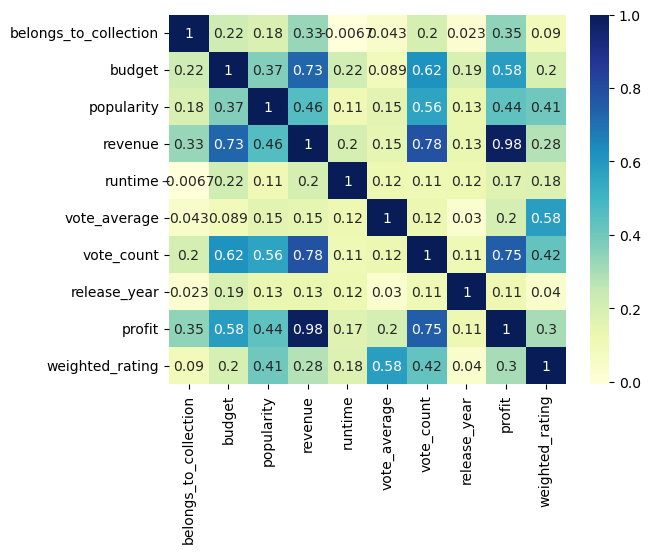

In [52]:
sns.heatmap(
    df.drop(columns=['id'], errors='ignore').corr(numeric_only=True),
    annot=True,
    cmap='YlGnBu'
)
plt.show()

As we can see, there are strong correlation (value > 0.7) between these:
- 0.73, budget and revenue
- 0.78, vote_count and revenue
- 0.75, profit and vote_count
- 0.98, profit and revenue

The more **revenue** a movie has, the more **profit** the movie will have and this result is expected therefore. However, other conclusions can be reached, too:
- If a movie has a higher **budget**, it is excpected to also have higher **revenue**.
- The more the **number of votes** a movie has, the more **revenue** and therefore **profit** the movie has. 

About 2nd part, it seemed logical, because number of votes also indicates the **popularity** of a movie and popular ones probably tends to have more **revenue**. However, the relationship between **popularity** and **vote_count** or **profit / revenue** is not so strong. This result is surprizing. However, we can still say that there is a moderate correlation between:
- 0.46, popularity and revenue
- 0.56, popularity and vote_count
- 0.44, popularity and profit
- 0.61, budget and vote_count

The most surprizing result was having almost no correlation between **vote_average** and any other parameter except **weighted_rating**. Because it seems logical that higher voted movies tends to have move popularity and revenue. However, this is not the case. On the other hand, after some processing of **vote_average** in order to create **weighted_rating**, some moderate correlations between **weighted_rating** and other parameters are seen:
- 0.41, popularity and weighted_rating
- 0.42, vote_count and weighted_rating
- 0.30, profit and weighted_rating

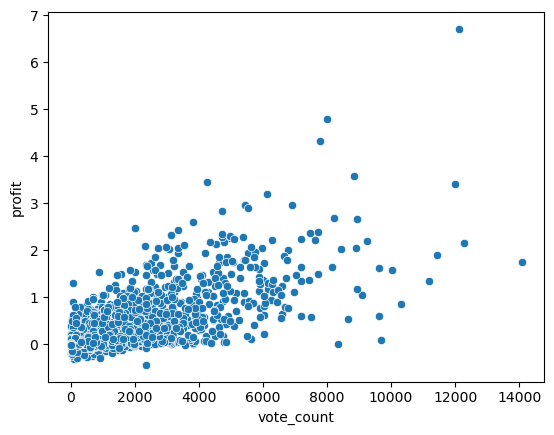

In [53]:
g = sns.scatterplot(x="vote_count", y="profit", data=df[["profit", "vote_count"]])

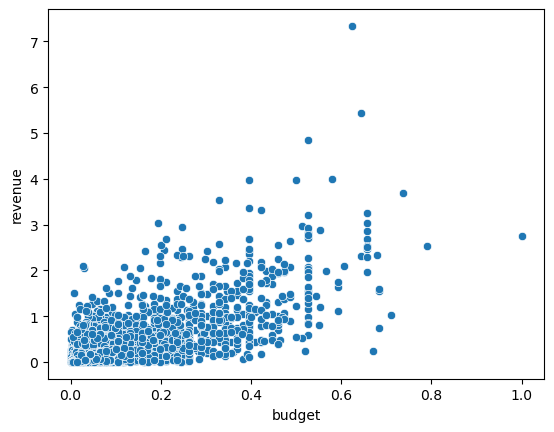

In [54]:
g = sns.scatterplot(x="budget", y="revenue", data=df[["budget", "revenue"]])

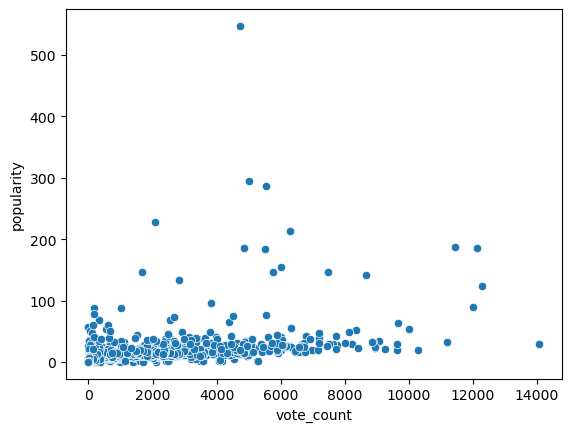

In [55]:
g = sns.scatterplot(x="vote_count", y="popularity", data=df[["popularity", "vote_count"]])

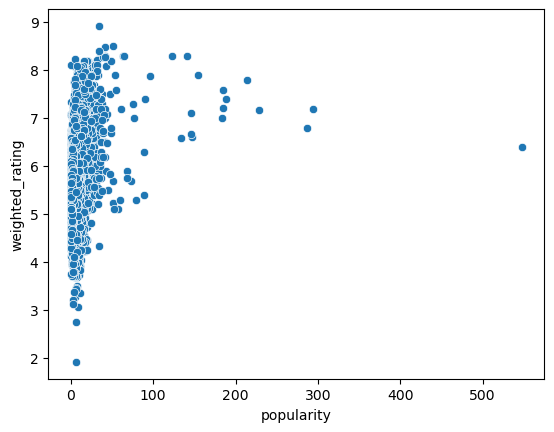

In [56]:
g = sns.scatterplot(x="popularity", y="weighted_rating", data=df[["popularity", "weighted_rating"]])

After the analysis of the numerical data, we can also look at the categorical data entries:

### - Genre Analysis
Let's construct a sub-dataset for specificly genres:

In [57]:
df_genres = df[["title", "genres", "popularity", "budget", "revenue", "vote_count", "weighted_rating"]]

In [58]:
df_genres.head()

,title,genres,popularity,budget,revenue,vote_count,weighted_rating
0,Toy Story,"[Animation, Comedy, Family]",21.946943,0.078949,0.983063,5415.0,7.684720
1,Jumanji,"[Adventure, Fantasy, Family]",17.015539,0.171057,0.691590,2413.0,6.877093
2,Grumpier Old Men,"[Romance, Comedy]",11.712900,NaN,NaN,92.0,6.165549
3,Waiting to Exhale,"[Comedy, Drama, Romance]",3.859495,0.042106,0.214353,34.0,5.681518
4,Father of the Bride Part II,[Comedy],8.387519,NaN,0.201529,173.0,5.626561


Now, let's create new columns for each genre type:

In [59]:
genres = list_counter(df_genres["genres"].values, log=False)

In [60]:
def list_to_col(data, col_name, col_list, limiter = 9999):
    counter = 0
    selected_items = set()
    for item in col_list:
        if counter >= limiter:
            break
        item = item[0]
        data[item] = 0
        selected_items.add(item)
        counter += 1
    
    for index, row in data.iterrows():
        for item in row[col_name]:  
            if item in selected_items:
                data.at[index, item] = 1
    data.drop([col_name], axis=1, inplace=True)
    return data

In [61]:
df_genres = list_to_col(df_genres, "genres", genres)
df_genres

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[item] = 0
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[item] = 0
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https

,title,popularity,budget,revenue,vote_count,weighted_rating,Drama,Comedy,Action,Thriller,...,Family,Mystery,Fantasy,Animation,Music,Foreign,History,War,Western,TV Movie
0,Toy Story,21.946943,0.078949,0.983063,5415.0,7.684720,0,1,0,0,...,1,0,0,1,0,0,0,0,0,0
1,Jumanji,17.015539,0.171057,0.691590,2413.0,6.877093,0,0,0,0,...,1,0,1,0,0,0,0,0,0,0
2,Grumpier Old Men,11.712900,NaN,NaN,92.0,6.165549,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Waiting to Exhale,3.859495,0.042106,0.214353,34.0,5.681518,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Father of the Bride Part II,8.387519,NaN,0.201529,173.0,5.626561,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45981,Robin Hood,5.683753,NaN,NaN,26.0,5.449586,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
45982,Century of Birthing,0.178241,NaN,NaN,3.0,5.645388,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
45983,Betrayal,0.903007,NaN,NaN,6.0,5.003042,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0
45984,Satan Triumphant,0.003503,NaN,NaN,0.0,5.100707,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [69]:
print(df_genres.columns.tolist())

['title', 'popularity', 'budget', 'revenue', 'vote_count', 'weighted_rating', 'Drama', 'Comedy', 'Action', 'Thriller', 'Romance', 'Horror', 'Crime', 'Documentary', 'Adventure', 'Science Fiction', 'Family', 'Mystery', 'Fantasy', 'Animation', 'Music', 'Foreign', 'History', 'War', 'Western', 'TV Movie']


Now, we can calculate average of **weighted_rating, vote_count, popularity, budget and revenue** for each type and compare the results:

In [70]:
def binary_mean_dataset_generator(data, col_list, limiter=9999):
    counter = 0
    items = []

    for item in col_list:
        if counter >= limiter:
            break
        items.append(item[0])
        counter += 1

    rows = []

    for item in items:
        value = data[data[item] == 1].mean(numeric_only=True)

        rows.append([
            item,
            value['popularity'],
            value['budget'],
            value['revenue'],
            value['vote_count'],
            value['weighted_rating']
        ])

    df_genres_means = pd.DataFrame(
        rows,
        columns=["type", "popularity", "budget", "revenue",
                 "vote_count", "rating"]
    )

    return df_genres_means

In [71]:
df_means_genres = binary_mean_dataset_generator(df_genres, genres)

df_means_genres

,type,popularity,budget,revenue,vote_count,rating
0,Drama,2.702574,0.044058,0.114397,85.712563,5.611167
1,Comedy,3.121826,0.054025,0.156932,104.399985,5.561425
2,Action,4.721392,0.097151,0.307257,257.586854,5.559755
3,Thriller,4.306521,0.056711,0.180011,176.954658,5.553581
4,Romance,3.006254,0.043798,0.124127,88.905401,5.599014
5,Horror,3.517725,0.024521,0.109326,100.134553,5.369289
6,Crime,4.061594,0.056469,0.149760,173.332420,5.697993
7,Documentary,0.946964,0.010105,0.021879,12.814684,5.542496
8,Adventure,5.916221,0.133134,0.464701,397.847214,5.659336
9,Science Fiction,4.672208,0.086862,0.343661,309.664579,5.479933


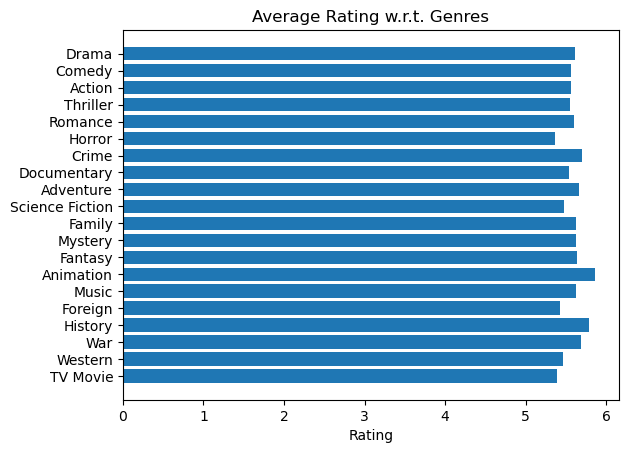

In [72]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_genres))
ax.barh(y_pos, df_means_genres['rating'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_genres['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Rating')
ax.set_title('Average Rating w.r.t. Genres')
plt.show()

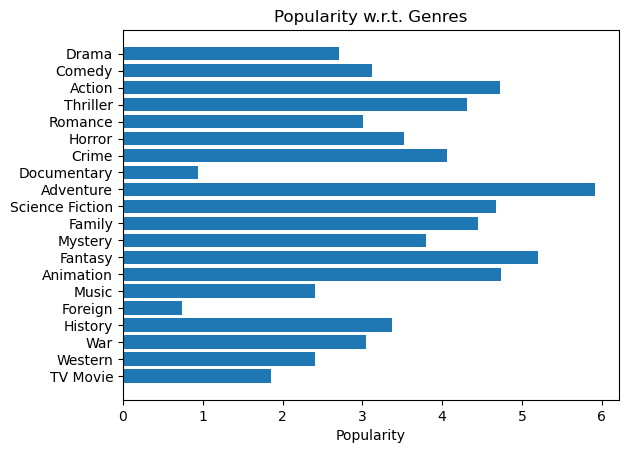

In [73]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_genres))
ax.barh(y_pos, df_means_genres['popularity'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_genres['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Popularity')
ax.set_title('Popularity w.r.t. Genres')
plt.show()

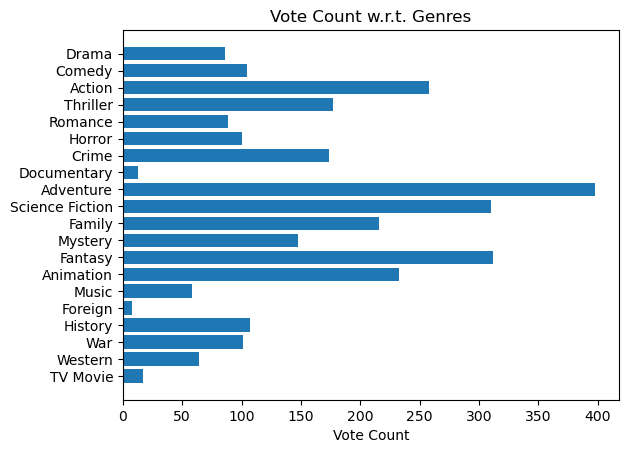

In [74]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_genres))
ax.barh(y_pos, df_means_genres['vote_count'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_genres['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Vote Count')
ax.set_title('Vote Count w.r.t. Genres')
plt.show()

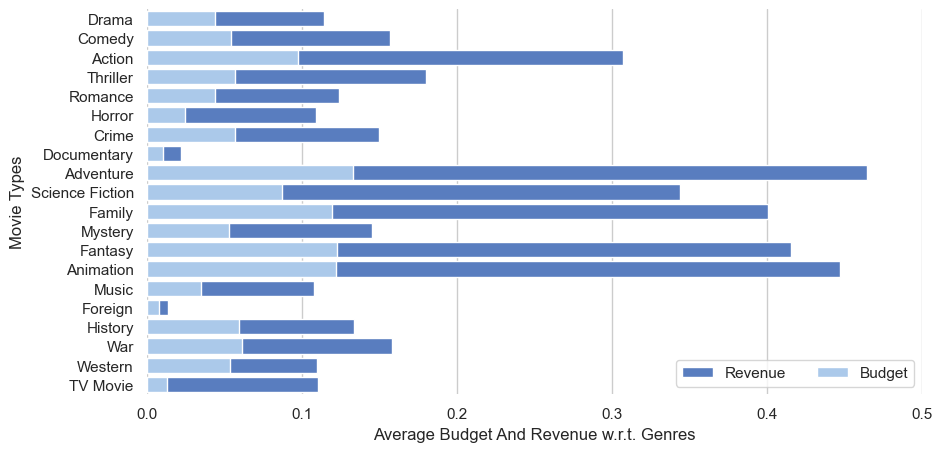

In [75]:
sns.set(style="whitegrid")
f, ax = plt.subplots(figsize=(10, 5))

sns.set_color_codes("muted")
sns.barplot(x="revenue", y="type", data=df_means_genres[['type', 'budget', 'revenue']],
            label="Revenue", color="b")

sns.set_color_codes("pastel")
sns.barplot(x="budget", y="type", data=df_means_genres[['type', 'budget', 'revenue']],
            label="Budget", color="b")

# Add a legend and informative axis label
ax.legend(ncol=2, loc="lower right", frameon=True)
ax.set(xlim=(0, 0.5), ylabel="Movie Types",
       xlabel="Average Budget And Revenue w.r.t. Genres")
sns.despine(left=True, bottom=True)

<Axes: >

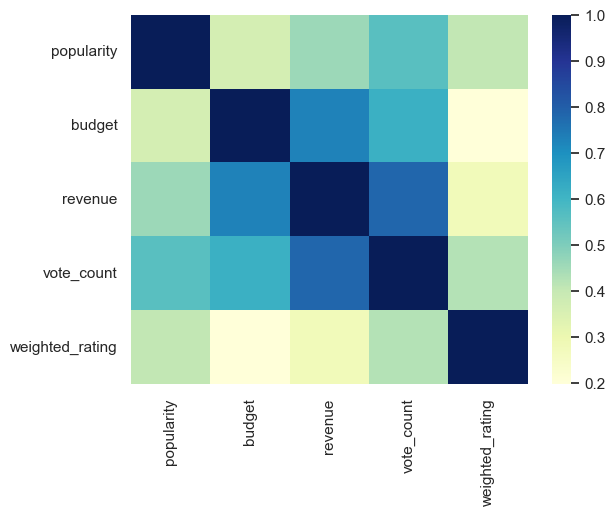

In [76]:
sns.heatmap(df_genres[["popularity", "budget", "revenue", "vote_count", "weighted_rating"]].corr(), 
            cmap = 'YlGnBu')

##### Results:
- About **average ratings**, genre has no significant effect.
- In **popularity, vote count, revenue**, especially adventure, fantasy, animation, science fiction, family and action gives higher values. For these 3 different aspects, the genre distributions are similar and thus we can conculde that these have correlation between each other.

### - Country Analysis
First of all, the same process made in **genres** has to be made. However, since there are many countries, first 10 will be analysed:

In [77]:
df_countries = df[["title", "production_countries", "popularity", "budget", "revenue", "vote_count", "weighted_rating"]]
countries = list_counter(df_countries["production_countries"].values, limiter=10, log=False)
df_countries = list_to_col(df_countries, "production_countries", countries, 10)
df_means_ct = binary_mean_dataset_generator(df_countries, countries)
df_means_ct 

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[item] = 0
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[item] = 0
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https

,type,popularity,budget,revenue,vote_count,rating
0,US,3.440773,0.068935,0.217194,154.847790,5.525979
1,GB,4.257017,0.069108,0.212111,186.155378,5.711879
2,FR,3.076935,0.048800,0.089747,89.538774,5.707020
3,DE,3.395118,0.074959,0.185220,143.364993,5.660565
4,IT,2.221366,0.039662,0.077377,45.933614,5.595083
5,CA,3.786445,0.050592,0.148372,131.219155,5.482829
6,JP,2.489934,0.052262,0.154224,60.510702,5.724528
7,ES,2.863088,0.041570,0.065081,75.395048,5.592001
8,RU,1.285705,0.021748,0.027639,18.530590,5.439132
9,IN,1.746378,0.025482,0.071883,40.888361,5.593713


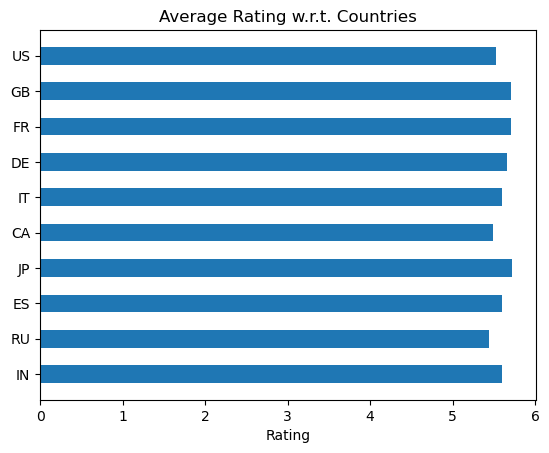

In [78]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_ct))
ax.barh(y_pos, df_means_ct['rating'], height=0.5, align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_ct['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Rating')
ax.set_title('Average Rating w.r.t. Countries')
plt.show()

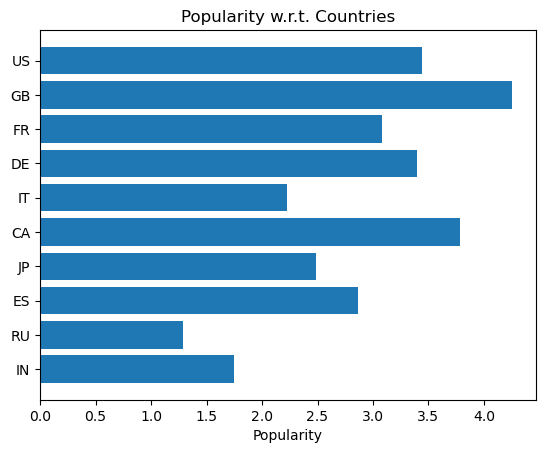

In [79]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_ct))
ax.barh(y_pos, df_means_ct['popularity'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_ct['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Popularity')
ax.set_title('Popularity w.r.t. Countries')
plt.show()

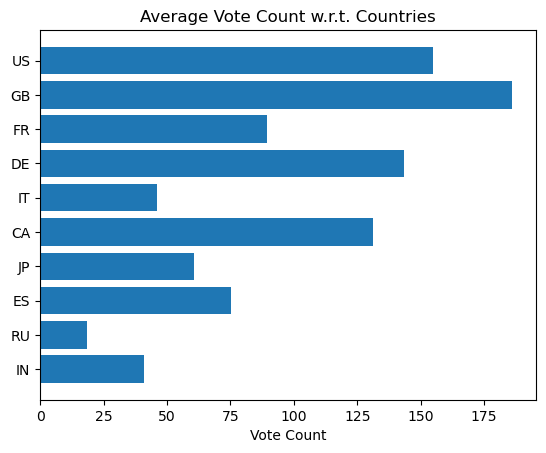

In [80]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_ct))
ax.barh(y_pos, df_means_ct['vote_count'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_ct['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Vote Count')
ax.set_title('Average Vote Count w.r.t. Countries')
plt.show()

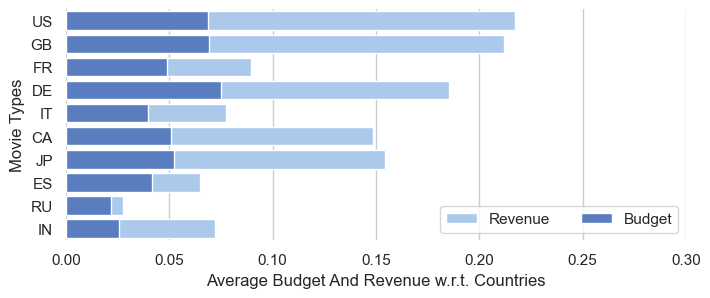

In [81]:
sns.set(style="whitegrid")
f, ax = plt.subplots(figsize=(8, 3))
sns.set_color_codes("pastel")
sns.barplot(x="revenue", y="type", data=df_means_ct[['type', 'budget', 'revenue']],
            label="Revenue", color="b")

sns.set_color_codes("muted")
sns.barplot(x="budget", y="type", data=df_means_ct[['type', 'budget', 'revenue']],
            label="Budget", color="b")

# Add a legend and informative axis label
ax.legend(ncol=2, loc="lower right", frameon=True)
ax.set(xlim=(0, 0.3), ylabel="Movie Types",
       xlabel="Average Budget And Revenue w.r.t. Countries")
sns.despine(left=True, bottom=True)

<Axes: >

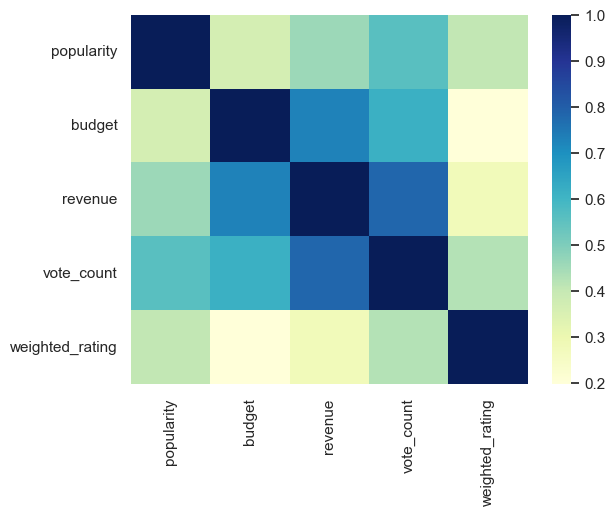

In [82]:
sns.heatmap(df_countries[["popularity", "budget", "revenue", "vote_count", "weighted_rating"]].corr(), 
            cmap = 'YlGnBu')

##### Results:
- About **average ratings**, genre has no significant effect.
- In **popularity**, the values differ w.r.t. countries. While for US, GB, CA, DE, FR the popularity is greater, for RU and IT the average popularity becomes lower.
- In **vote count, revenue**, especially US, GB, DE, CA, JP gives higher values. For these 2 different aspects, the genre distributions are similar and thus we can conculde that these have correlation between each other. For some countries like US, **popularity** feature gives also similar rankings.

### - Director Analysis

In [83]:
df_dir= df[["title", "director", "popularity", "budget", "revenue", "vote_count", "weighted_rating"]]
df_dir.dropna(subset=["director"], inplace=True)
directors = df_dir["director"].value_counts()
directors = directors.index.to_list()

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\2812393368.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dir.dropna(subset=["director"], inplace=True)


In [84]:
def str_to_col(data, col_name, col_list, limiter = 9999):
    counter = 0
    selected = set()
    for item in col_list:
        if counter >= limiter:
            break
        data[item] = 0
        selected.add(item)
        counter += 1
    for index, row in data.iterrows():
        item = row[col_name]
        if(item in selected):
            data.at[index, item] = 1
    data.drop([col_name], axis=1, inplace=True)
    return data

In [88]:
def str_mean_dataset_generator(data, col_list, limiter=9999):
    counter = 0
    items = []

    for item in col_list:
        if counter >= limiter:
            break
        items.append(item)
        counter += 1

    rows = []

    for item in items:
        value = data[data[item] == 1].mean(numeric_only=True)

        rows.append([
            item,
            value['popularity'],
            value['budget'],
            value['revenue'],
            value['vote_count'],
            value['weighted_rating']
        ])

    df_genres_means = pd.DataFrame(
        rows,
        columns=["type", "popularity", "budget", "revenue",
                 "vote_count", "rating"]
    )

    return df_genres_means

In [91]:
print(df_dir.columns.tolist())

['title', 'popularity', 'budget', 'revenue', 'vote_count', 'weighted_rating', 'John Ford', 'Michael Curtiz', 'Werner Herzog', 'Alfred Hitchcock', 'Georges MÃ©liÃ¨s', 'Woody Allen', 'Jean-Luc Godard', 'Sidney Lumet', 'George Cukor', 'Charlie Chaplin', 'Raoul Walsh', 'William A. Wellman', 'Henry Hathaway', 'Martin Scorsese', 'Julien Duvivier']


In [94]:
for item in directors[:15]:
    print(item)
    print(df_dir[item].value_counts(dropna=False))
    print("Count of 1:", (df_dir[item] == 1).sum())
    print("-------------------")

John Ford
John Ford
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Michael Curtiz
Michael Curtiz
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Werner Herzog
Werner Herzog
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Alfred Hitchcock
Alfred Hitchcock
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Georges MÃ©liÃ¨s
Georges MÃ©liÃ¨s
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Woody Allen
Woody Allen
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Jean-Luc Godard
Jean-Luc Godard
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Sidney Lumet
Sidney Lumet
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
George Cukor
George Cukor
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Charlie Chaplin
Charlie Chaplin
0    45147
Name: count, dtype: int64
Count of 1: 0
-------------------
Raou

In [96]:
df_dir = df.copy()

In [97]:
print('director' in df_dir.columns)

True


In [98]:
df_dir = str_to_col(df_dir, "director", directors[:15], 15)

In [99]:
df_means_dir = str_mean_dataset_generator(df_dir, directors[:15])

df_means_dir

,type,popularity,budget,revenue,vote_count,rating
0,John Ford,3.015273,0.007210,0.022414,33.014925,5.707650
1,Michael Curtiz,2.080021,0.004921,0.019904,37.515152,5.550251
2,Werner Herzog,2.350419,0.012803,0.016167,47.127273,5.913140
3,Alfred Hitchcock,6.498370,0.005337,0.031343,240.981132,6.372877
4,Georges MÃ©liÃ¨s,0.645268,0.001774,NaN,16.580000,5.488653
5,Woody Allen,7.673525,0.034755,0.096881,316.571429,6.451967
6,Jean-Luc Godard,2.137694,0.000688,0.000902,31.617021,5.828494
7,Sidney Lumet,3.903939,0.027142,0.059622,114.934783,5.888937
8,George Cukor,4.580770,0.015798,0.097819,26.533333,5.577959
9,Charlie Chaplin,2.822399,0.006636,0.011632,85.181818,5.996946


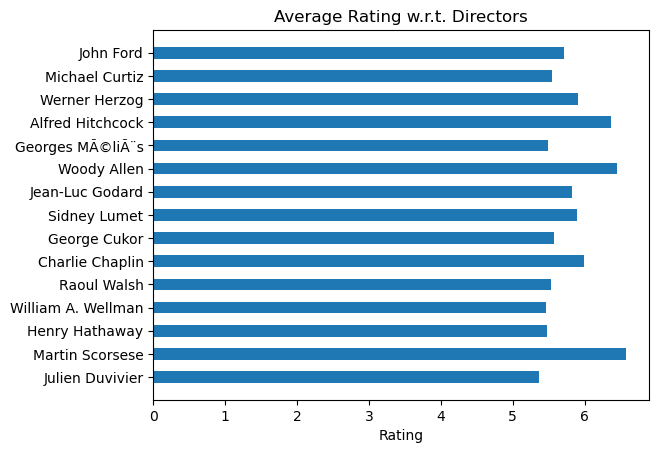

In [100]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_dir))
ax.barh(y_pos, df_means_dir['rating'], height=0.5, align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_dir['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Rating')
ax.set_title('Average Rating w.r.t. Directors')
plt.show()

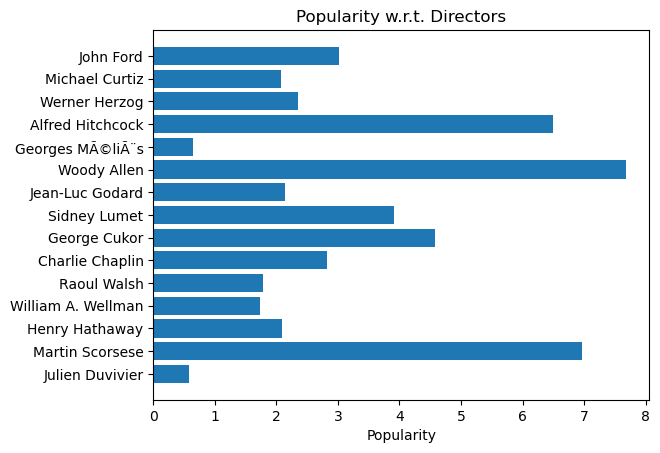

In [101]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_dir))
ax.barh(y_pos, df_means_dir['popularity'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_dir['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Popularity')
ax.set_title('Popularity w.r.t. Directors')
plt.show()

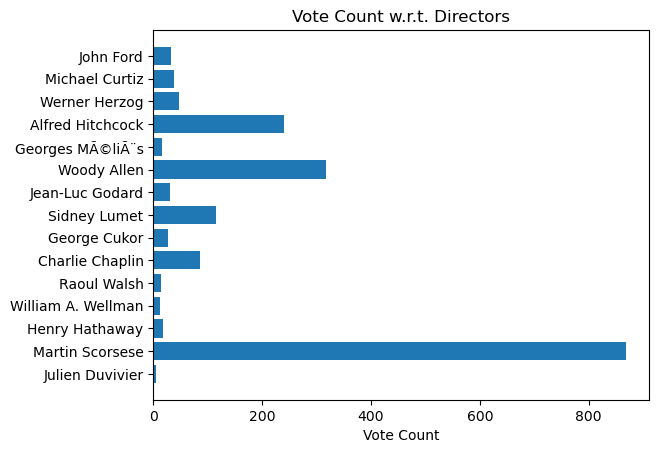

In [102]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_dir))
ax.barh(y_pos, df_means_dir['vote_count'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_dir['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Vote Count')
ax.set_title('Vote Count w.r.t. Directors')
plt.show()

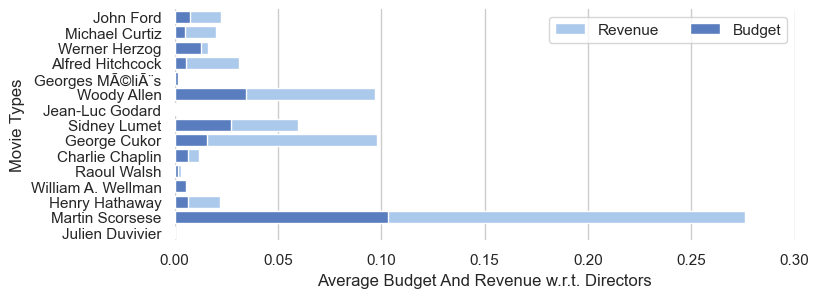

In [103]:
sns.set(style="whitegrid")
f, ax = plt.subplots(figsize=(8, 3))
sns.set_color_codes("pastel")
sns.barplot(x="revenue", y="type", data=df_means_dir[['type', 'budget', 'revenue']],
            label="Revenue", color="b")

sns.set_color_codes("muted")
sns.barplot(x="budget", y="type", data=df_means_dir[['type', 'budget', 'revenue']],
            label="Budget", color="b")

# Add a legend and informative axis label
ax.legend(ncol=2, loc="upper right", frameon=True)
ax.set(xlim=(0, 0.3), ylabel="Movie Types",
       xlabel="Average Budget And Revenue w.r.t. Directors")
sns.despine(left=True, bottom=True)

<Axes: >

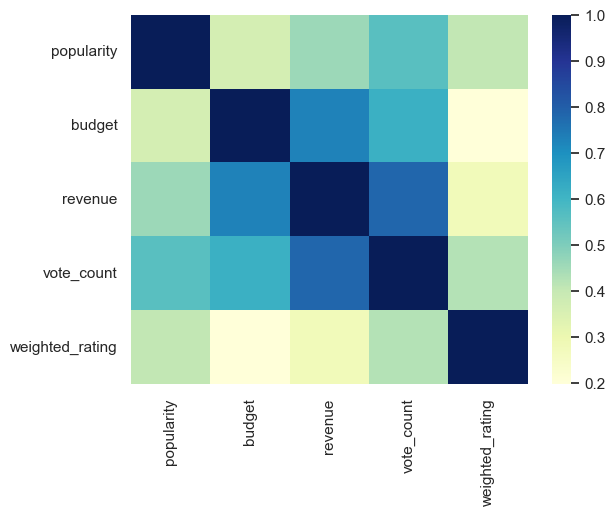

In [104]:
sns.heatmap(df_dir[["popularity", "budget", "revenue", "vote_count", "weighted_rating"]].corr(), 
            cmap = 'YlGnBu')

##### Results:
- In **average ratings**, the values differ regarding the director. The highest rating belongs to Martin Scorsese and the lowest one is Julien Duvivier's.
- In **popularity**, the value difference between directors significantly increases. However, the ones thathave higher **average ratings** usually haves higher **popularity** values, too (and vice versa). Therefore, **average_ratings** and **popularity** may have a significant correlation between each other.
- In **vote count and revenue & budget**, Martin Scorsese has a great difference from all the other directors. But also, the ones that have higher values in previous categories are higher again compared to others.

### - Keyword Analysis

In [105]:
df_key = df[["title", "keywords", "popularity", "budget", "revenue", "vote_count", "weighted_rating"]]
df_key.dropna(subset=["keywords"], inplace=True)
keywords = list_counter(df_key["keywords"].values, 20, log=False)
df_key = list_to_col(df_key, "keywords", keywords)
df_means_key = binary_mean_dataset_generator(df_key, keywords, 20)
df_means_key

C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\2246120331.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_key.dropna(subset=["keywords"], inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[item] = 0
C:\Users\Admin\AppData\Local\Temp\ipykernel_13924\666913143.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/p

,type,popularity,budget,revenue,vote_count,rating
0,woman director,1.413522,0.022752,0.049277,19.971486,5.432956
1,independent film,2.296209,0.011377,0.010173,27.626943,5.501637
2,based on novel,6.080021,0.089237,0.250349,352.079260,5.839264
3,musical,2.580680,0.053114,0.175483,70.709375,5.572462
4,sex,4.468153,0.031791,0.084637,119.347826,5.540791
5,female nudity,3.800495,0.024543,0.071193,85.207143,5.452621
6,biography,3.171936,0.044140,0.098351,116.736944,5.777555
7,murder,2.820432,0.029556,0.076525,59.873239,5.469207
8,sport,3.275109,0.047848,0.092427,86.517241,5.582513
9,prison,5.352645,0.057373,0.154333,219.557143,5.938344


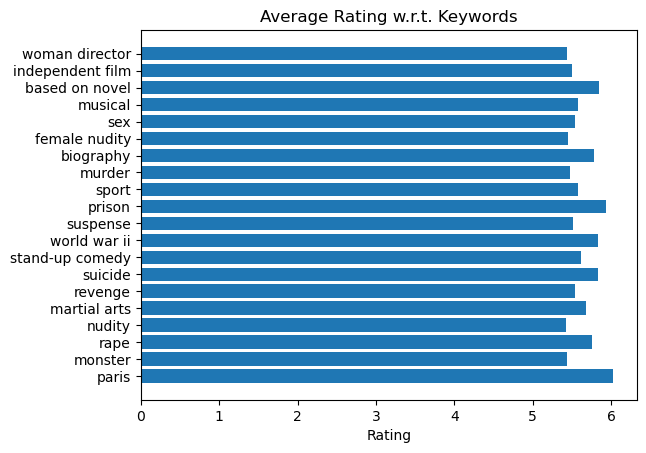

In [106]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_key))
ax.barh(y_pos, df_means_key['rating'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_key['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Rating')
ax.set_title('Average Rating w.r.t. Keywords')
plt.show()

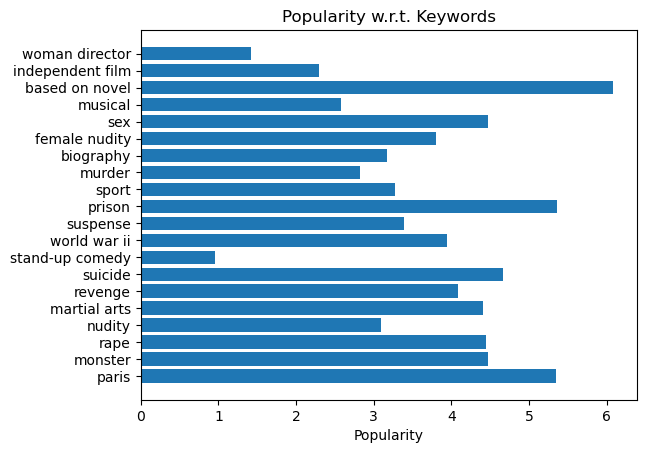

In [107]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_key))
ax.barh(y_pos, df_means_key['popularity'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_key['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Popularity')
ax.set_title('Popularity w.r.t. Keywords')
plt.show()

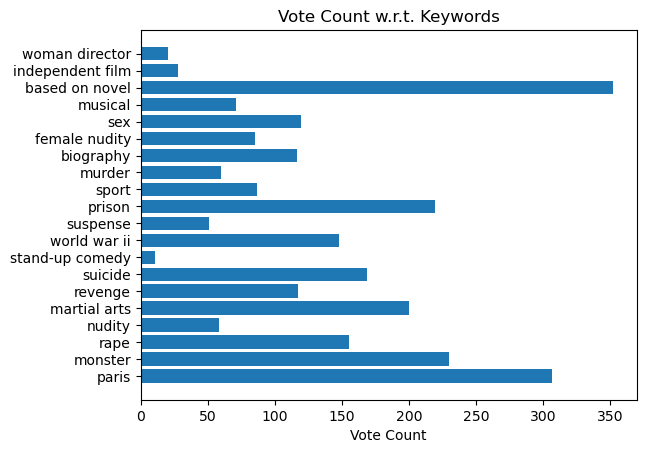

In [108]:
plt.rcdefaults()
fig, ax = plt.subplots()
y_pos = np.arange(len(df_means_key))
ax.barh(y_pos, df_means_key['vote_count'], align='center')
ax.set_yticks(y_pos)
ax.set_yticklabels(df_means_key['type'])
ax.invert_yaxis()  # labels read top-to-bottom
ax.set_xlabel('Vote Count')
ax.set_title('Vote Count w.r.t. Keywords')
plt.show()

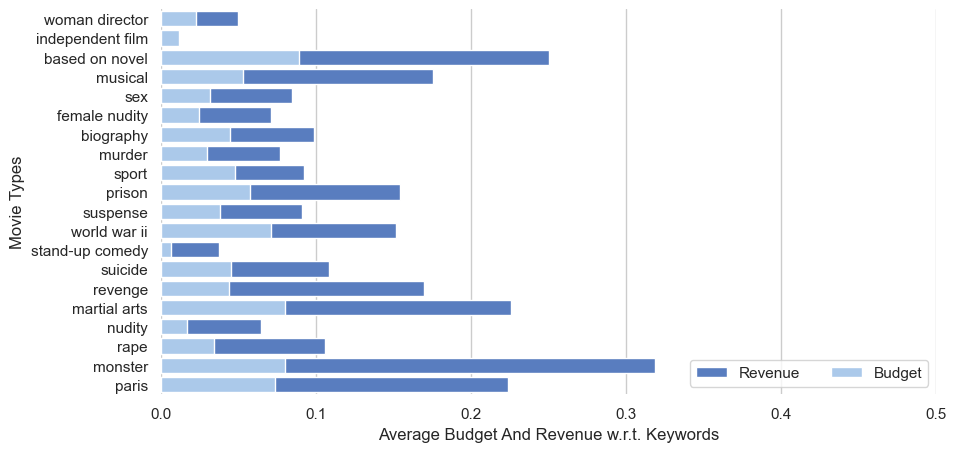

In [109]:
sns.set(style="whitegrid")
f, ax = plt.subplots(figsize=(10, 5))

sns.set_color_codes("muted")
sns.barplot(x="revenue", y="type", data=df_means_key[['type', 'budget', 'revenue']],
            label="Revenue", color="b")

sns.set_color_codes("pastel")
sns.barplot(x="budget", y="type", data=df_means_key[['type', 'budget', 'revenue']],
            label="Budget", color="b")

# Add a legend and informative axis label
ax.legend(ncol=2, loc="lower right", frameon=True)
ax.set(xlim=(0, 0.5), ylabel="Movie Types",
       xlabel="Average Budget And Revenue w.r.t. Keywords")
sns.despine(left=True, bottom=True)

<Axes: >

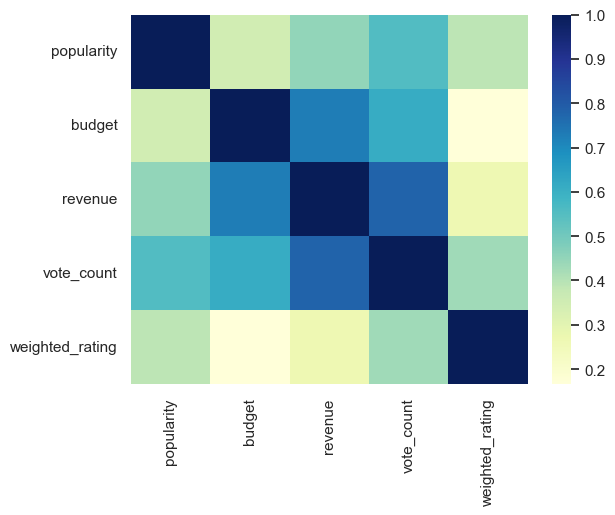

In [110]:
sns.heatmap(df_key[["popularity", "budget", "revenue", "vote_count", "weighted_rating"]].corr(), 
            cmap = 'YlGnBu')

##### Results:
- In **average ratings**, the values differ not so significantly.
- In **popularity**, the value difference between keywords significantly increases. The most popular keywords are: *based on novel, prison, sex, paris*.
- In **vote count** again the most popular ones are the same with the most popular ones. However, when a movie is **based on a novel** then the aoumt of votes significantly higher than other categories.
- In revenue & budget**, the movies with **monsters** profits more than others in average.

### - Director and Cast Correlation
First, top directors and casts have to be placed to columns. Since there are too many people in these categories, top 10 of each category will be selected:

In [111]:
df_cast_dir = df[["director", "cast"]].dropna()
df_cast_dir.head()

,director,cast
0,John Lasseter,"[Tom Hanks, Tim Allen, Don Rickles]"
1,Joe Johnston,"[Robin Williams, Jonathan Hyde, Kirsten Dunst]"
2,Howard Deutch,"[Walter Matthau, Jack Lemmon, Ann-Margret]"
3,Forest Whitaker,"[Whitney Houston, Angela Bassett, Loretta Devine]"
4,Charles Shyer,"[Steve Martin, Diane Keaton, Martin Short]"


Directors are assigned into columns:

In [112]:
director_list = df_cast_dir["director"].value_counts()
director_list = director_list.index.to_list()
df_cast_dir = str_to_col(df_cast_dir, "director", director_list[:10], 10)

Cast is assigned into columns:

In [113]:
cast = list_counter(df_cast_dir["cast"].values, 10, log=False)
df_cast_dir = list_to_col(df_cast_dir, "cast", cast, 10)

Rows with all zeros are removed:

In [114]:
df_cast_dir = df_cast_dir.loc[(df_cast_dir!=0).any(axis=1)]

Correlation of the table is investigated:

In [115]:
df_cast_dir.shape

(1273, 20)

<Axes: >

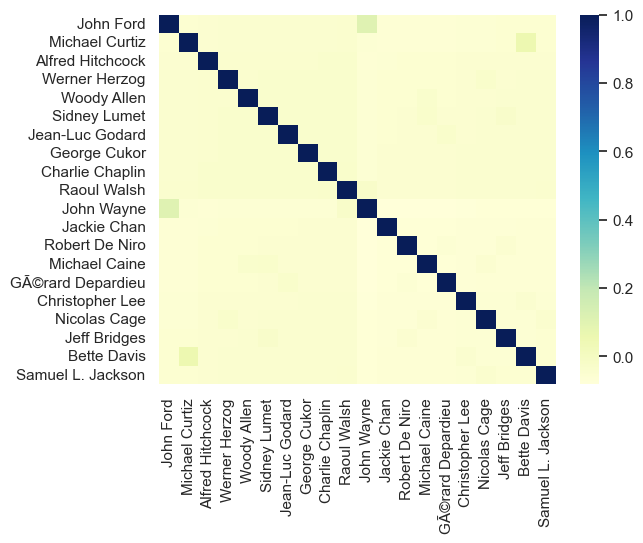

In [116]:
sns.heatmap(df_cast_dir.corr(), cmap = 'YlGnBu')